# Proyek 3: K-Means Clustering dengan Cosine Similarity (Spherical K-Means) pada BISINDO

**Metrik Jarak:** Cosine Distance (1 - Cosine Similarity)  
**Representasi Fitur:** 127 Dimensi MediaPipe (42 Titik 3D + Is_Two_Handed)  
**Jumlah Klaster:** K = 26 (Alfabet A-Z)  
**Fungsi Objektif:** Angular Inertia / Spherical Dispersion  
**Output Target:** `outputKmeans/elbow_cosine.png`, `outputKmeans/cluster_cosine.png`, `outputKmeans/evaluasi_kmeans_cosine.xlsx`

---

## 1. Landasan Teori & Formulasi Matematis

Jarak deviasi sudut orientasi antara dua vektor gestur dalam ruang berdimensi 127:
$$d_{\text{Cosine}}(x, y) = 1 - \frac{x \cdot y}{\|x\|_2 \|y\|_2}$$

Fungsi dispersi angular yang diminimalkan:
$$J_{\text{Cosine}} = \sum_{k=1}^{26} \sum_{x \in S_k} \left(1 - \frac{x \cdot \mu_k}{\|x\|_2 \|\mu_k\|_2}\right)$$

Prinsip Spherical K-Means memperbarui titik pusat pada permukaan bola satuan hiperdimensi ($\|x\|_2 = 1$):
$$\mu_k^* = \frac{\sum_{x \in S_k} x}{\left\|\sum_{x \in S_k} x\right\|_2}$$
Metrik ini mengabaikan panjang fisik lengan atau ukuran tangan pengguna, murni mengelompokkan kesamaan sudut bentuk jari.

In [1]:
# =======================================================================
# 1. SETUP LINGKUNGAN & PUSTAKA
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    pairwise_distances
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "outputKmeans")
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42
K_BENCHMARK = 26
np.random.seed(RANDOM_STATE)

print(f"[INFO] Direktori: {BASE_DIR} | K Benchmark = {K_BENCHMARK}")

[INFO] Direktori: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\KMeans | K Benchmark = 26


In [2]:
# =======================================================================
# PEMUATAN DATASET BISINDO LANDMARKS (127 FITUR)
# =======================================================================
npz_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz")
csv_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.csv")

if os.path.exists(npz_path):
    data = np.load(npz_path, allow_pickle=True)
    X = data['X'].astype(np.float32)
    labels = data['labels']
    df_meta = pd.DataFrame({'label': labels, 'is_two_handed': data['is_two_handed']})
elif os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    meta_cols = ['label', 'label_idx', 'filename', 'num_hands', 'is_flip']
    meta_present = [c for c in meta_cols if c in df_full.columns]
    df_meta = df_full[meta_present]
    feat_cols = [c for c in df_full.columns if c not in meta_cols]
    X = df_full[feat_cols].values.astype(np.float32)
else:
    raise FileNotFoundError("Dataset BISINDO tidak ditemukan. Jalankan extract_features.py.")

print(f"[INFO] Dataset BISINDO dimuat: {X.shape[0]} sampel, {X.shape[1]} dimensi fitur.")

# Standarisasi dan dilanjutkan Normalisasi L2 ke unit hypersphere
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

normalizer = Normalizer(norm='l2')
X_norm = normalizer.fit_transform(X_std)
print("[INFO] Fitur dinormalisasi L2 ke permukaan bola satuan (||x|| = 1).")

[INFO] Dataset BISINDO dimuat: 7893 sampel, 127 dimensi fitur.
[INFO] Fitur dinormalisasi L2 ke permukaan bola satuan (||x|| = 1).


[ELBOW] Menghitung inersia deviasi Cosine...


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\KMeans\outputKmeans\elbow_cosine.png'


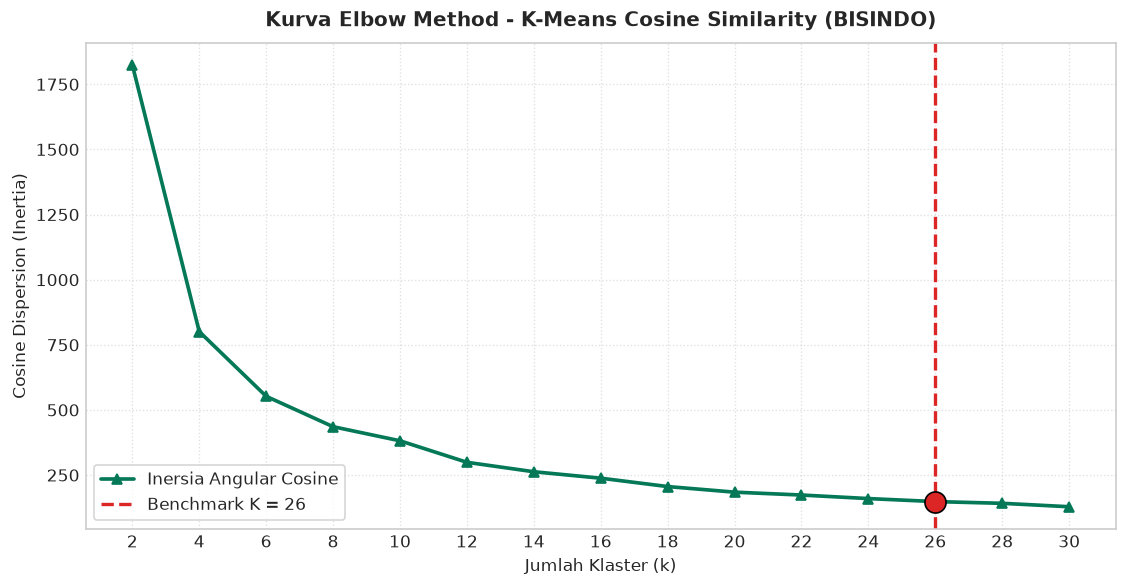

In [3]:
# =======================================================================
# 2. KURVA ELBOW METHOD COSINE (ANGULAR INERTIA)
# =======================================================================
k_range = list(range(2, 32, 2))
if K_BENCHMARK not in k_range:
    k_range.append(K_BENCHMARK)
k_range = sorted(k_range)

cos_inertia = []
print("[ELBOW] Menghitung inersia deviasi Cosine...")
for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=3, max_iter=150, random_state=RANDOM_STATE)
    km.fit(X_norm)
    # Cosine distance = 1 - dot product on normalized vectors
    dists = pairwise_distances(X_norm, km.cluster_centers_, metric='cosine')
    min_d = np.min(dists, axis=1)
    cos_inertia.append(np.sum(min_d ** 2))

plt.figure(figsize=(9.5, 5))
plt.plot(k_range, cos_inertia, marker='^', linewidth=2.2, color='#047857', label='Inersia Angular Cosine')
plt.axvline(x=K_BENCHMARK, color='#DC2626', linestyle='--', linewidth=2, label=f'Benchmark K = {K_BENCHMARK}')

idx_26 = k_range.index(K_BENCHMARK)
plt.scatter([K_BENCHMARK], [cos_inertia[idx_26]], color='#DC2626', s=160, zorder=5, edgecolor='black')

plt.title('Kurva Elbow Method - K-Means Cosine Similarity (BISINDO)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Jumlah Klaster (k)', fontsize=10)
plt.ylabel('Cosine Dispersion (Inertia)', fontsize=10)
plt.xticks(k_range)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()

elbow_path = os.path.join(OUTPUT_DIR, "elbow_cosine.png")
plt.savefig(elbow_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{elbow_path}'")
plt.show()

In [4]:
# =======================================================================
# 3. IMPLEMENTASI DAN PELATIHAN SPHERICAL K-MEANS PADA K = 26
# =======================================================================
class KMeansCosine:
    def __init__(self, n_clusters=26, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = 0.0
        self.n_iter_ = 0
        self.execution_time_ = 0.0

    def fit(self, X):
        start = time.perf_counter()
        rng = np.random.RandomState(self.random_state)
        n_samples = len(X)

        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms[norms == 0] = 1e-10
        X_calc = X / norms

        centroids = [X_calc[rng.randint(n_samples)]]
        for _ in range(1, self.n_clusters):
            dists = pairwise_distances(X_calc, np.array(centroids), metric='cosine')
            min_d = np.min(dists, axis=1) ** 2
            probs = min_d / np.sum(min_d)
            centroids.append(X_calc[rng.choice(n_samples, p=probs)])
        
        centroids = np.array(centroids)
        c_norms = np.linalg.norm(centroids, axis=1, keepdims=True)
        c_norms[c_norms == 0] = 1e-10
        self.centroids = centroids / c_norms

        for it in range(self.max_iter):
            self.n_iter_ = it + 1
            dists = pairwise_distances(X_calc, self.centroids, metric='cosine')
            labels = np.argmin(dists, axis=1)

            new_c = np.zeros_like(self.centroids)
            for k in range(self.n_clusters):
                pts = X_calc[labels == k]
                if len(pts) > 0:
                    mean_v = np.mean(pts, axis=0)
                    norm_v = np.linalg.norm(mean_v)
                    new_c[k] = mean_v / (norm_v if norm_v > 0 else 1.0)
                else:
                    new_c[k] = X_calc[rng.randint(n_samples)]

            if np.linalg.norm(new_c - self.centroids) < self.tol:
                self.centroids = new_c
                self.labels_ = labels
                break
            self.centroids = new_c
            self.labels_ = labels

        final_d = pairwise_distances(X_calc, self.centroids, metric='cosine')
        self.inertia_ = float(np.sum(final_d[np.arange(len(X_calc)), self.labels_] ** 2))
        self.execution_time_ = float(time.perf_counter() - start)
        return self

print("[PELATIHAN] Melatih Spherical KMeans (Cosine) K=26...")
model_cos = KMeansCosine(n_clusters=K_BENCHMARK, random_state=RANDOM_STATE).fit(X_norm)
print(f"[SELESAI] Konvergen dalam {model_cos.n_iter_} iterasi ({model_cos.execution_time_:.3f}s)")

[PELATIHAN] Melatih Spherical KMeans (Cosine) K=26...


[SELESAI] Konvergen dalam 25 iterasi (0.173s)


In [5]:
# =======================================================================
# 4. EVALUASI METRIK DAN EKSPOR EXCEL COSINE
# =======================================================================
sil = float(silhouette_score(X_norm, model_cos.labels_, metric='cosine'))
db = float(davies_bouldin_score(X_norm, model_cos.labels_))
ch = float(calinski_harabasz_score(X_norm, model_cos.labels_))

df_res = pd.DataFrame([{
    'Distance Metric': 'Cosine Similarity (Spherical)',
    'Clusters (K)': K_BENCHMARK,
    'Silhouette Score (↑)': round(sil, 4),
    'Davies–Bouldin Index (↓)': round(db, 4),
    'Calinski–Harabasz Index (↑)': round(ch, 2),
    'Execution Time (s) (↓)': round(model_cos.execution_time_, 4),
    'Iterations (↓)': model_cos.n_iter_,
    'Objective Value (J)': round(model_cos.inertia_, 2)
}])

print("\n" + "="*75)
print(df_res.to_string(index=False))
print("="*75)

excel_out = os.path.join(OUTPUT_DIR, "evaluasi_kmeans_cosine.xlsx")
df_data_out = df_meta.copy()
df_data_out['cluster_cosine'] = model_cos.labels_

with pd.ExcelWriter(excel_out, engine='openpyxl') as writer:
    df_res.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)
    df_data_out.to_excel(writer, sheet_name='Data_Terklaster', index=False)
print(f"[SAVE] Laporan Excel disimpan ke: '{excel_out}'")


              Distance Metric  Clusters (K)  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)  Iterations (↓)  Objective Value (J)
Cosine Similarity (Spherical)            26                0.3334                    1.4964                      1120.34                  0.1727              25               154.32


[SAVE] Laporan Excel disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\KMeans\outputKmeans\evaluasi_kmeans_cosine.xlsx'


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\KMeans\outputKmeans\cluster_cosine.png'


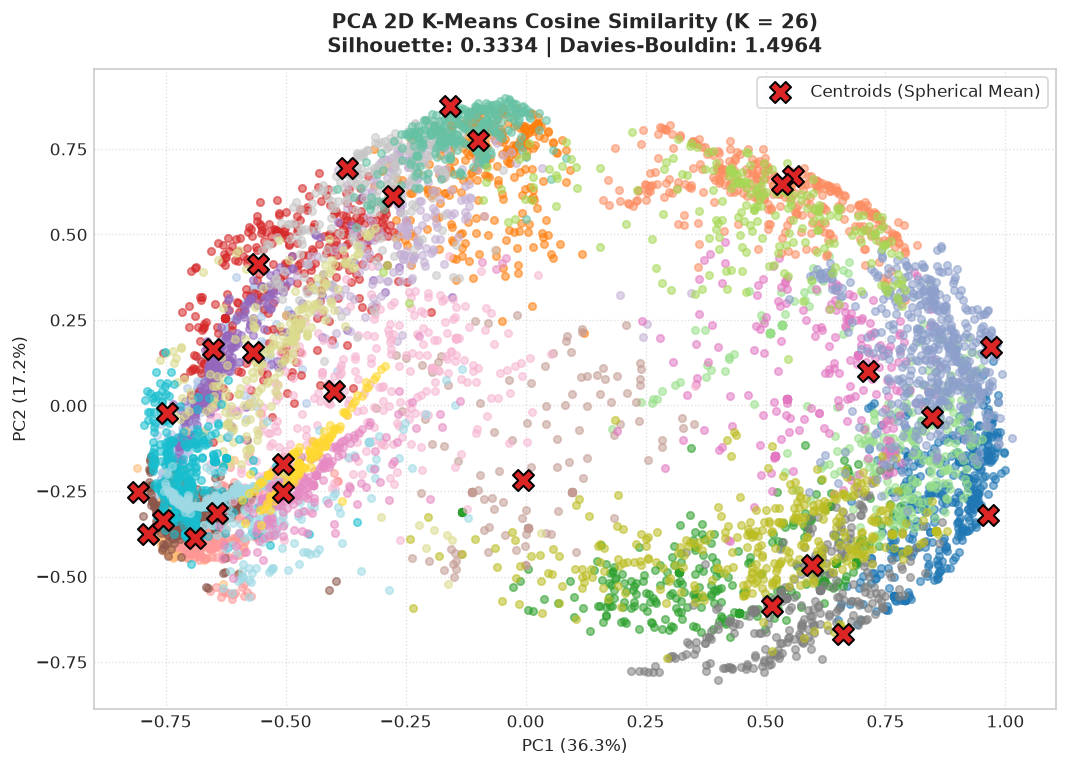

In [6]:
# =======================================================================
# 5. VISUALISASI PCA 2D KLASTERISASI COSINE
# =======================================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_norm)
centroids_pca = pca.transform(model_cos.centroids)

plt.figure(figsize=(9, 6.5))
palette = sns.color_palette("tab20", 20) + sns.color_palette("Set2", 6)

for k in range(K_BENCHMARK):
    mask = (model_cos.labels_ == k)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], color=palette[k % len(palette)], alpha=0.55, s=20)

plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker='X', s=160, c='#DC2626', edgecolor='black', linewidth=1.2, label='Centroids (Spherical Mean)', zorder=10)
plt.title(f'PCA 2D K-Means Cosine Similarity (K = {K_BENCHMARK})\nSilhouette: {sil:.4f} | Davies-Bouldin: {db:.4f}', fontsize=12, fontweight='bold', pad=10)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, loc='best')
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_cosine.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{cluster_path}'")
plt.show()